# 13-FreeRTOS计数信号量与资源数量管理


## 1. 本篇内容与学习目标

本篇对应《FreeRTOS 从入门到实战》中的 `18计数信号量.pptx`，围绕计数信号量的“0～最大值”计数特性，学习它如何记录多个事件、管理多个同类资源，并通过按键与 LED 案例理解完整使用流程。

| 课件主线 | 本篇学习内容 |
|---|---|
| 基本概念 | 计数范围、初始计数和最大计数 |
| 核心 API | 创建、获取、释放、查询当前计数 |
| 机制对比 | 与二值信号量的边界和选型 |
| 应用场景 | 多信号累积、多资源共享、生产者—消费者 |

主课件共19页，第19页为品牌结束页；教学内容覆盖第1—18页。副本同样19页，第18页为核心小结，第19页为品牌结束页。示例代码用于解释 API 和任务协作，未声称完成特定开发板的编译、下载或运行。


## 2. 什么是计数信号量

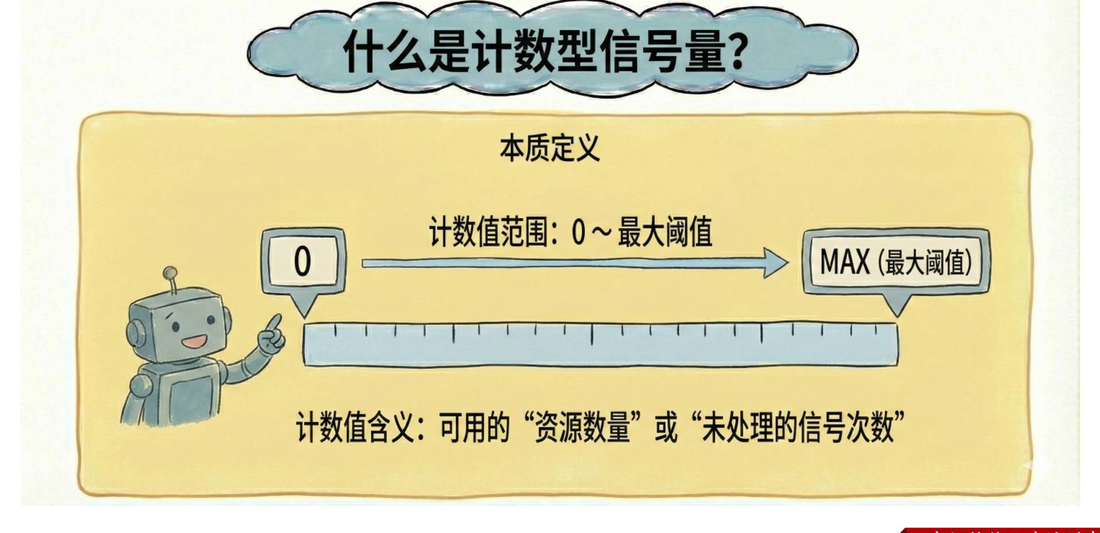

计数信号量可以理解为一个公共“钥匙盒”，盒中钥匙数量可以从0增加到设定的最大值 `uxMaxCount`。计数值可以表示两类信息：

- **可用资源数量**：例如有3个相同的串口缓冲区，计数值为3表示3个都可用。
- **尚未处理的信号次数**：生产者释放一次，计数加1；消费者获取一次，计数减1。

它只记录数量，不携带事件的具体内容。若还需要传递传感器数值、数据包或结构体，应使用消息队列等数据通道。


## 3. 计数信号量的形象模型与核心优势

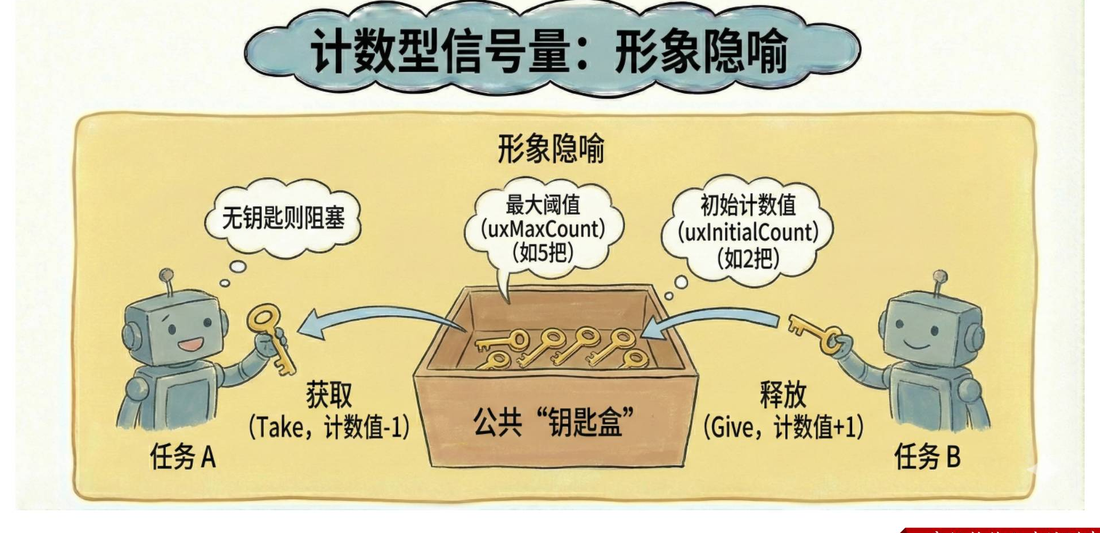

计数信号量和二值信号量都使用 Take/Give，但计数范围不同：

| 对比维度 | 计数信号量 | 二值信号量 |
|---|---|---|
| 计数范围 | `0 ～ uxMaxCount` | 只有0或1 |
| 典型含义 | 多个事件或多个同类资源 | 一次通知或单个资源可用 |
| 释放效果 | 计数值加1，可连续累积 | 最多保持为1，重复释放不保存次数 |
| 创建接口 | `xSemaphoreCreateCounting()` | `xSemaphoreCreateBinary()` |

因此，计数信号量能在接收任务暂时未运行时保存多次 Give，等任务恢复后逐个 Take；也能限制同时访问资源的任务数量。


## 4. 创建计数信号量：`xSemaphoreCreateCounting`

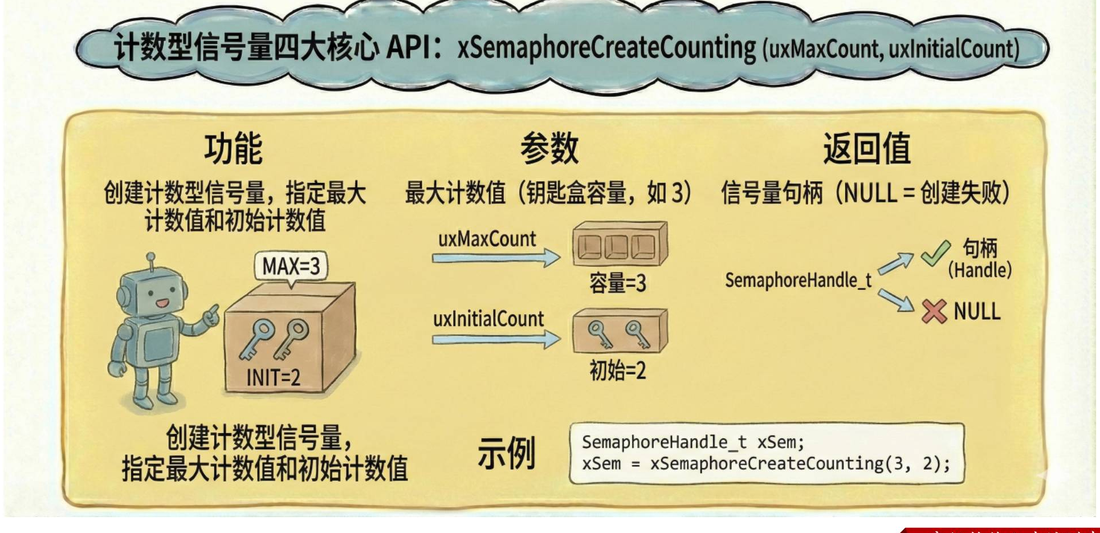

核心原型为：

```c
SemaphoreHandle_t xSemaphoreCreateCounting(
    UBaseType_t uxMaxCount,
    UBaseType_t uxInitialCount
);
```

- `uxMaxCount`：允许的最大计数，也是钥匙盒容量。
- `uxInitialCount`：创建完成时的初始可用数量，必须满足 `uxInitialCount <= uxMaxCount`。
- 返回值：成功返回信号量句柄，失败返回 `NULL`。

例如创建容量为3、初始有2把钥匙的计数信号量：

```c
SemaphoreHandle_t xSem;
xSem = xSemaphoreCreateCounting(3, 2);
if (xSem == NULL) {
    // 需要检查堆空间、动态分配配置和对象数量
    handle_create_error();
}
```

动态创建会占用 FreeRTOS 堆。创建失败不是“句柄暂时不可用”，调用前应先检查 `NULL`，并根据工程的 `configTOTAL_HEAP_SIZE` 与 heap 实现排查内存不足。


## 5. 获取信号量：计数值减一

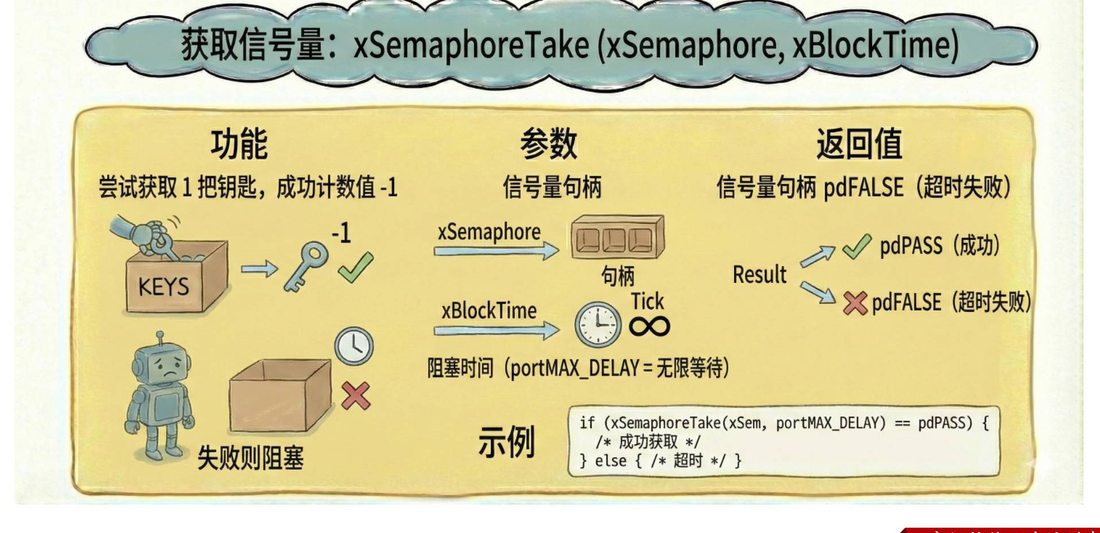

`xSemaphoreTake(xSemaphore, xBlockTime)` 尝试获取一把钥匙。成功时计数值减1并返回 `pdPASS`（与 `pdTRUE` 等值）；当前计数为0时，根据阻塞时间等待：

```c
if (xSemaphoreTake(xSem, pdMS_TO_TICKS(1000)) == pdPASS) {
    use_one_resource();
} else {
    handle_timeout();
}
```

| 阻塞参数 | 行为 |
|---|---|
| `0` | 立即尝试，没资源就返回失败 |
| `pdMS_TO_TICKS(1000)` | 最多等待1000毫秒 |
| `portMAX_DELAY` | 当 `INCLUDE_vTaskSuspend == 1` 时可表示无限等待；否则是有限最大 tick |

阻塞等待期间任务让出 CPU，调度器可以运行其他就绪任务。`xBlockTime` 是等待资源的最长时间，不是资源处理时长；拿到资源后仍应尽快完成访问并释放。


## 6. 释放信号量：计数值加一

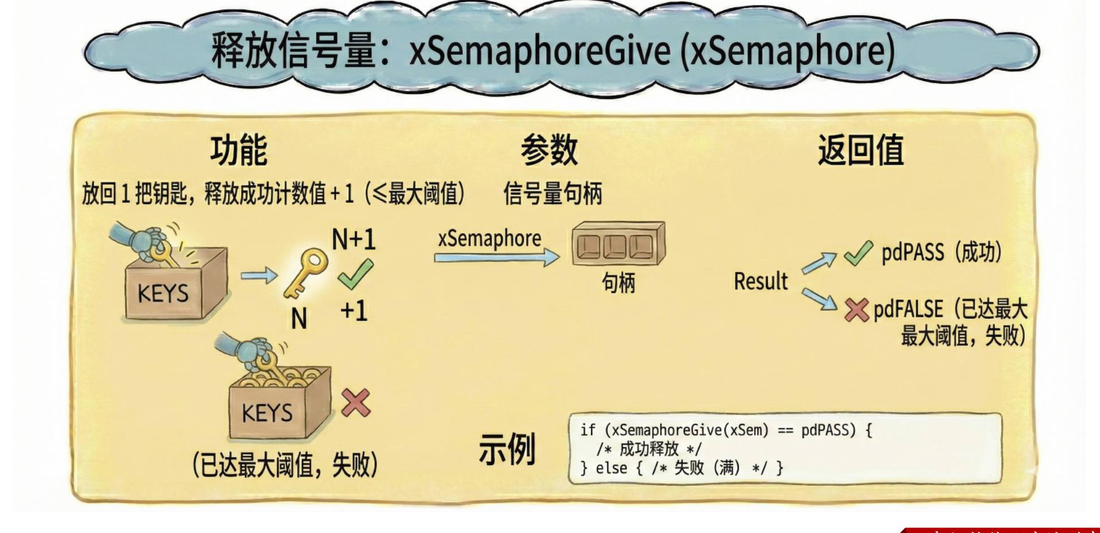

`xSemaphoreGive(xSemaphore)` 归还一把钥匙，成功时计数值加1，但不能超过 `uxMaxCount`：

```c
if (xSemaphoreGive(xSem) != pdPASS) {
    // 已达到最大计数，释放动作没有可增加的空间
    log_give_failure();
}
```

计数达到最大值时继续 Give 会返回失败，说明调用方可能重复归还、初始化计数过大，或者资源所有权管理有问题。释放成功后，阻塞在 Take 上的任务可能被唤醒；被唤醒只代表进入就绪态，实际运行还要由调度器决定。

如果释放动作发生在 ISR 中，必须使用对应的 `xSemaphoreGiveFromISR()`，并根据 `pxHigherPriorityTaskWoken` 请求一次切换；普通任务 API 不能直接用于中断上下文。


## 7. 查询当前计数：`uxSemaphoreGetCount`

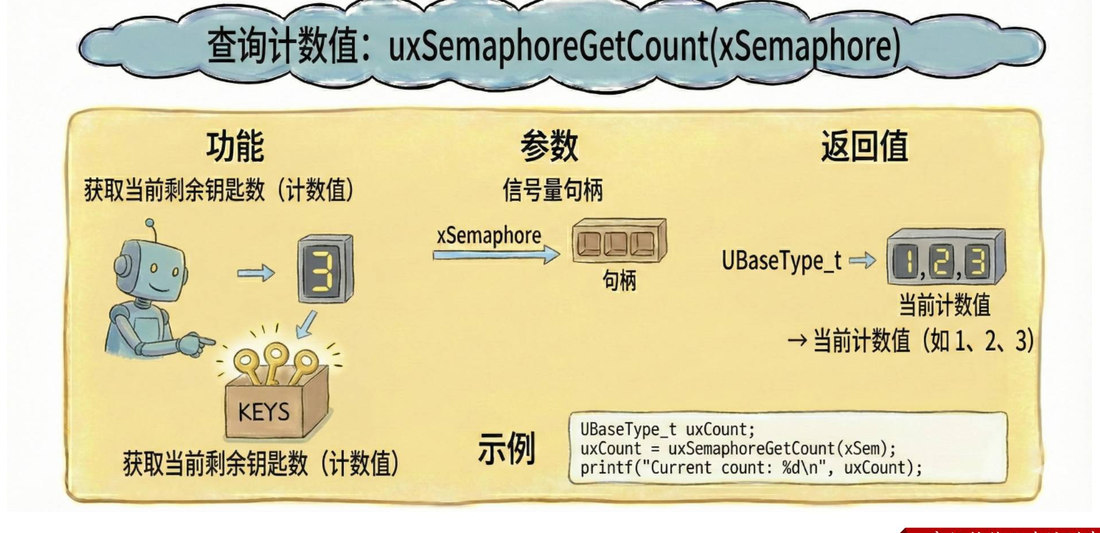

可以使用：

```c
UBaseType_t uxCount = uxSemaphoreGetCount(xSem);
printf("Current count: %lu\\n", (unsigned long)uxCount);
```

该接口返回当前剩余钥匙数，适合调试、状态监控和容量观察。例如，创建时为2，连续两次 Take 后计数变为0；每次 Give 成功后计数再增加。查询结果是瞬时快照，多任务环境下读取后可能立即被其他任务改变，不能把一次查询和后续操作当作不可分割的事务。

在中断中需要读取计数时，应查阅所用 FreeRTOS 版本是否提供适用的 ISR 版本，不能自行把普通 API 当成中断安全接口。


## 8. 按键多次触发 LED：计数信号量案例

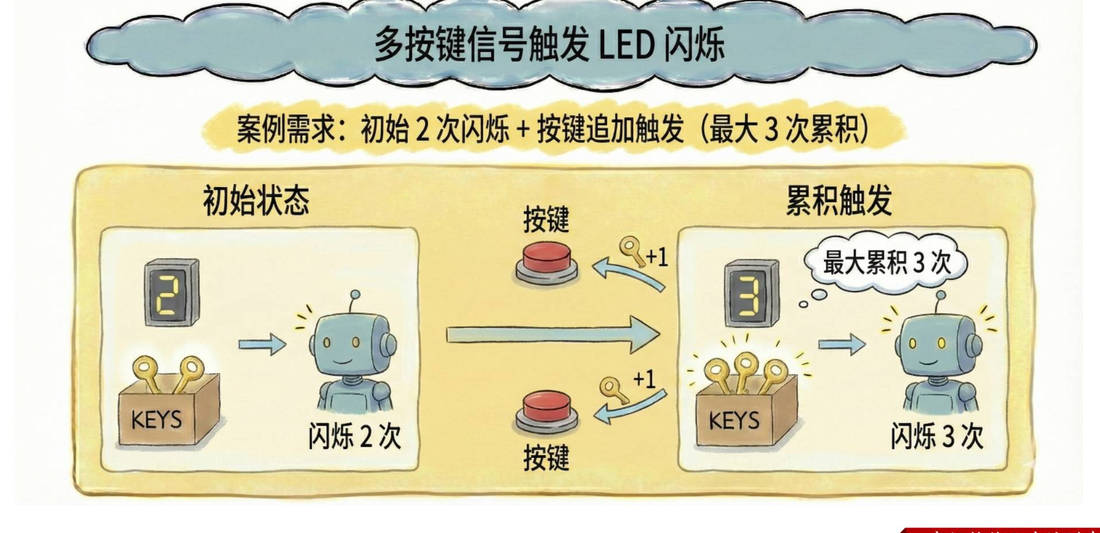

课件案例要求：LED 初始闪烁2次，按键每按下一次再增加1次，最多累积到3次。计数信号量把“尚未处理的闪烁次数”保存下来：

```c
static SemaphoreHandle_t xLedCount;

void led_task(void *arg)
{
    for (;;) {
        if (xSemaphoreTake(xLedCount, portMAX_DELAY) == pdPASS) {
            led_toggle_once();
        }
    }
}

void key_task(void *arg)
{
    for (;;) {
        if (key1_pressed()) {
            (void)xSemaphoreGive(xLedCount); // 满计数时应记录失败
            debounce_delay();
        }
        scan_delay();
    }
}
```

上面是说明性流程：真实的 `key1_pressed()`、LED GPIO 和消抖逻辑要替换为板级驱动。初始化时可按课件设置 `xLedCount = xSemaphoreCreateCounting(3, 2)`，表示开始已有2次待处理信号；任务创建和句柄返回值仍需在工程中检查。


## 9. 三类典型应用场景

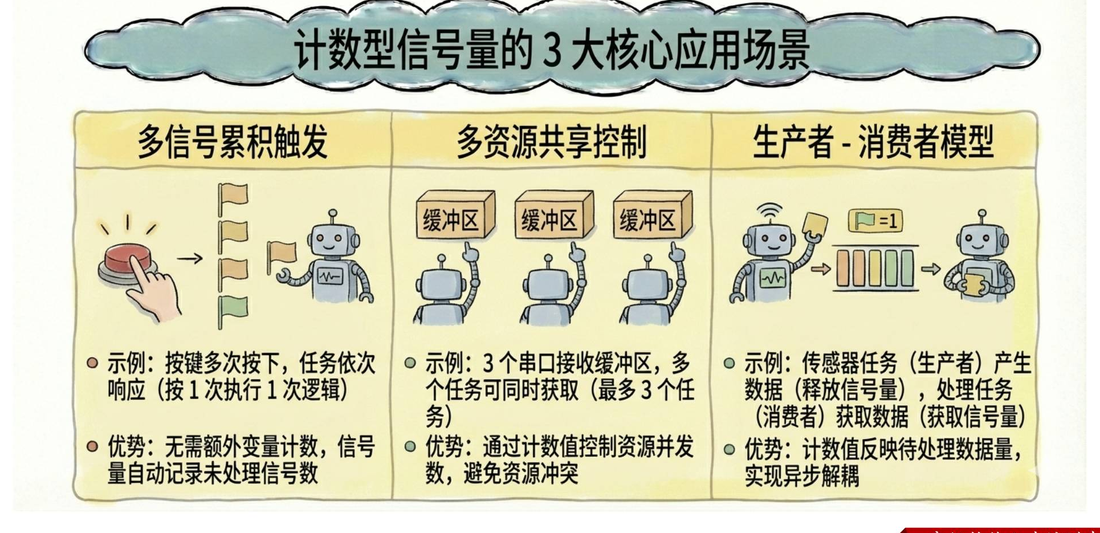

1. **多信号累积触发**：按键、传感器或中断连续产生事件，消费者任务稍后逐个处理，不需要额外维护事件计数变量。
2. **多资源共享控制**：系统有3个同类缓冲区或连接槽位，计数初始化为3；每次 Take 占用一个，使用结束 Give 归还一个，从而限制并发数量。
3. **生产者—消费者模型**：生产者完成一项工作就 Give，消费者 Take 后处理。计数值代表待处理项目数，但具体项目内容仍需放在队列、环形缓冲区等数据结构中。

计数信号量只解决“有多少个许可/事件”，不解决“每个事件对应什么数据”以及数据本身的互斥保护。


## 10. 与二值信号量的选型边界

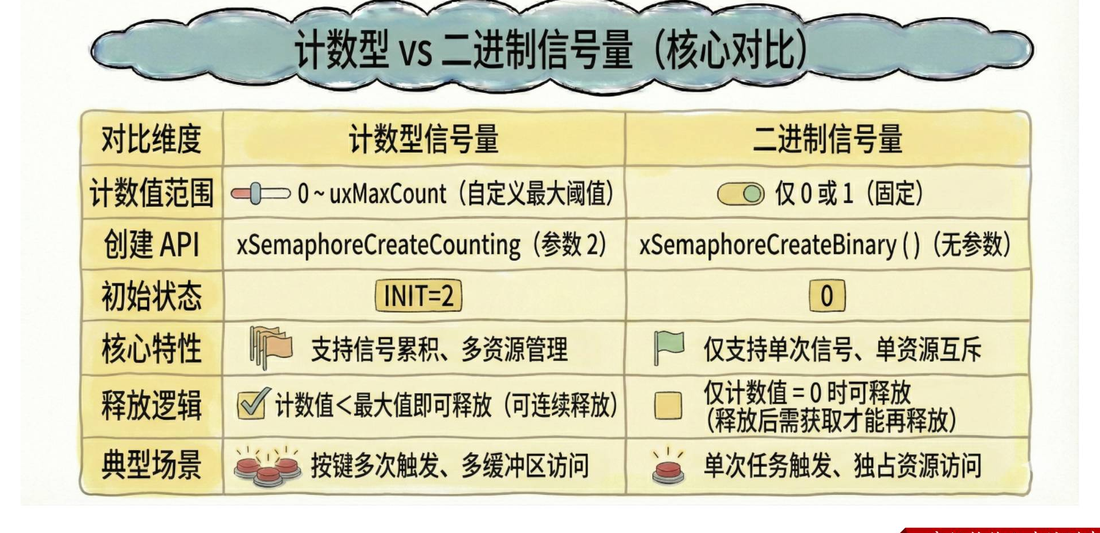

可以按以下问题选择：

- 需要累计多次事件吗？需要时优先考虑计数信号量；只关心“发生过一次”时二值信号量更直接。
- 需要同时允许多个任务使用同类资源吗？把最大计数设为资源数量，并让每次使用成对 Take/Give。
- 需要保护临界区并要求所有权、优先级继承吗？应评估互斥信号量；计数信号量没有“谁拥有资源”的语义。

二值信号量的容量固定为1，计数信号量的价值在于“计数灵活性”。不要因为多个任务都能调用 Take，就把它误当成自动提供数据队列或严格互斥锁。


## 11. 常见问题与排查清单

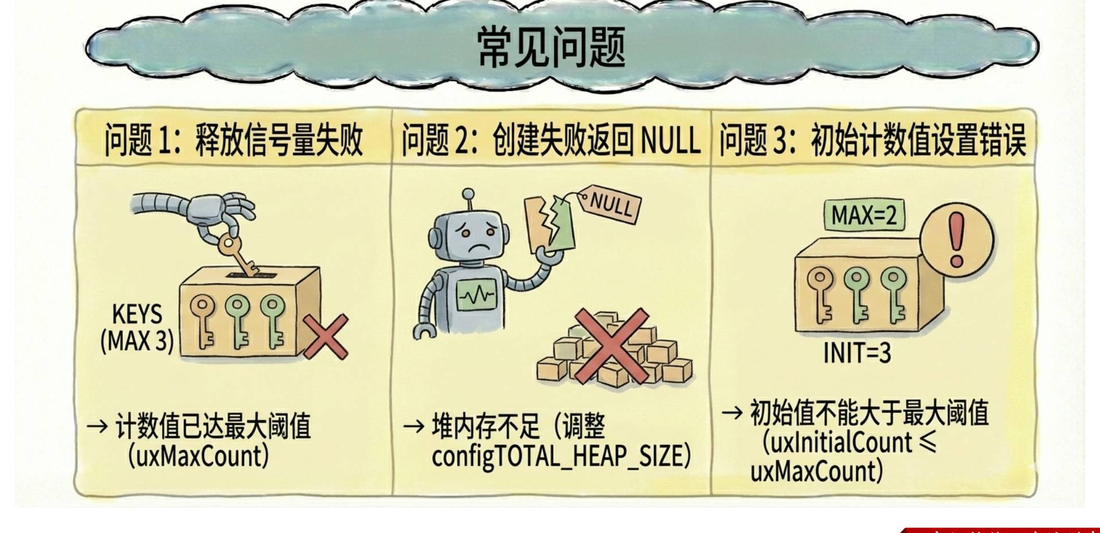

### 释放失败

通常是当前计数已经达到 `uxMaxCount`。检查是否重复 Give、初始化和最大值是否合理，以及资源归还路径是否成对。

### 创建返回 `NULL`

优先检查动态分配是否开启、heap 空间是否足够、任务和其他内核对象是否占用了大量内存，并在创建后立即判断句柄。

### 初始计数大于最大计数

必须满足 `uxInitialCount <= uxMaxCount`。容量为2时不能用初始值3；应修正参数或重新评估资源数量。

### ISR 或优先级误用

中断中只调用 FromISR 版本；计数减少的先后顺序由调度顺序决定，不能把“谁先拿到”当成优先级反转机制。需要严格优先级继承时，应重新选择同步原语。


## 12. 核心总结

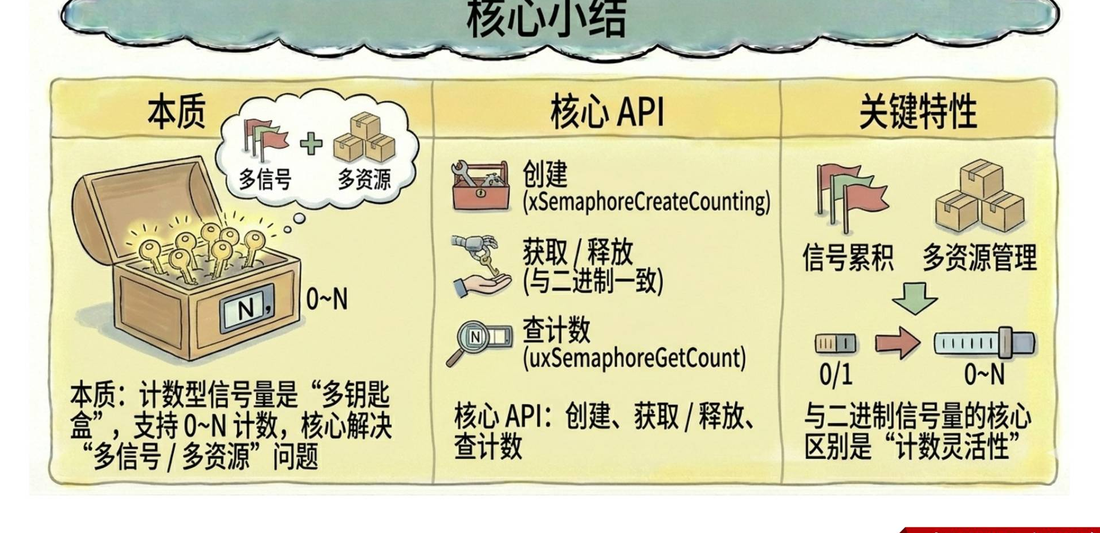

- **本质**：计数信号量是一个可容纳 `0～uxMaxCount` 把钥匙的公共盒子，可表示可用资源数量或未处理信号次数。
- **核心 API**：`xSemaphoreCreateCounting()` 创建，`xSemaphoreTake()` 获取并减1，`xSemaphoreGive()` 释放并加1，`uxSemaphoreGetCount()` 查询当前计数。
- **关键边界**：计数不能超过最大值；初始值不能大于最大值；普通任务和 ISR 必须使用各自适用的 API。
- **选型原则**：多事件累积和多资源管理优先考虑计数信号量；单次通知用二值信号量；数据传递用消息队列；所有权与优先级继承需求评估互斥信号量。

本篇只依据课程 PPT 和 API 语义整理，未进行开发板编译、下载或运行验证。

> API 返回值补充：pdPASS/pdTRUE 表示成功，pdFALSE/pdFAIL 表示超时或释放失败，实际判断应以 API 返回值为准。
